# Large Ontix Tuning Visualization

### Load results

In [124]:
# Load all pkl in folder which end with '__tuning.pkl'
import os
import pickle
import glob
import pandas as pd
import numpy as np

def load_tuning_results(folder_path):
	tuning_files = glob.glob(os.path.join(folder_path, '*_tuning.pkl'))
	all_results = dict()

	for file in tuning_files:
		with open(file, 'rb') as f:
			data = pickle.load(f)
			ontology_name = os.path.basename(file).replace('_tuning.pkl', '').replace('large_ontix_', '').replace('_ontology_task', '')
			all_results[ontology_name] = data

	return all_results

folder_path = '../results/large_ontix_save/run_Aug26/'  


tuning_results = load_tuning_results(folder_path)


In [125]:
tuning_results.keys()

dict_keys(['Dim32_KimiK3', 'Dim48_ClaudeOpus5', 'Dim48_GPT5.6_TerraPro', 'Dim16_GPT5.6_TerraPro', 'Dim32_GPT5.6_TerraPro', 'Dim16_ClaudeOpus5', 'Dim32_ClaudeOpus5', 'Dim16_KimiK3', 'Dim48_KimiK3'])

In [126]:
df_list = []
for ontology_name, tuning in tuning_results.items():
	# Store best ml_performance and recon_loss till trial_id
	best_ml_performance = -np.inf
	best_recon_loss = np.inf
	tuning.results['best_ml_performance'] = np.nan # Initialize column
	tuning.results['best_recon_loss'] = np.nan # Initialize column
	tuning.results['is_best'] = False # Initialize column

	for idx, row in tuning.results.sort_values('trial_id').iterrows():
		trial_id = row['trial_id']
		
		ml_performance = row['ml_performance']
		recon_loss = row['recon_loss']

		if ml_performance > best_ml_performance:
			best_ml_performance = ml_performance

		
		if recon_loss < best_recon_loss:
			best_recon_loss = recon_loss
	
		tuning.results.at[idx, 'best_ml_performance'] = best_ml_performance
		tuning.results.at[idx, 'best_recon_loss'] = best_recon_loss
	
	idx_best = tuning.results['ml_performance'].idxmax()
	tuning.results.at[idx_best, 'is_best'] = True
	tuning.results['ontology_dim'] = ontology_name.split('_')[0]
	tuning.results['ontology_name'] = ontology_name
	if len(ontology_name.split('_')) > 1:
		tuning.results['LLM'] = ontology_name.split('_')[1]
	else:
		tuning.results['LLM'] = 'Varix'
	# df_list.append(tuning.results.loc[:, ['trial_id', 'ml_performance', 'recon_loss', 'best_ml_performance', 'best_recon_loss', 'LLM', 'ontology_dim']])
	df_list.append(tuning.results)

plot_df = pd.concat(df_list, ignore_index=True)

# Order ontology_name so Dim16 < Dim32 < Dim48 and, within a dim, Claude < GPT < Kimi
def _ontology_sort_key(name):
	dim_str, *rest = name.split('_')
	dim_num = int(dim_str.replace('Dim', ''))
	llm = '_'.join(rest) if rest else 'Varix'
	return (dim_num, llm)

ontology_order = sorted(plot_df['ontology_name'].unique(), key=_ontology_sort_key)
plot_df['ontology_name'] = pd.Categorical(plot_df['ontology_name'], categories=ontology_order, ordered=True)

plot_df

,ml_performance,recon_loss,ml_perf_celltype,ml_perf_other,var_celltype_performance,var_other_performance,st_worker_timestamp,st_worker_time,st_worker_iter,st_decision,...,config_beta,config_learning_rate,config_n_layers,st_tuner_time,best_ml_performance,best_recon_loss,is_best,ontology_dim,ontology_name,LLM
0,0.784541,964.097954,0.835311,0.733772,0.003085,0.011344,1.787306e+09,0.000010,0,CONTINUE,...,0.010464,0.000055,5,2550.399300,0.874778,815.242098,False,Dim32,Dim32_KimiK3,KimiK3
1,0.735597,924.402474,0.782839,0.688356,0.002909,0.009105,1.787306e+09,0.000018,0,CONTINUE,...,0.001788,0.034319,5,2640.680912,0.874778,815.242098,False,Dim32,Dim32_KimiK3,KimiK3
2,0.872802,734.254114,0.925383,0.820221,0.002128,0.014679,1.787306e+09,0.000008,0,CONTINUE,...,0.000019,0.003754,5,2680.838167,0.874778,734.254114,False,Dim32,Dim32_KimiK3,KimiK3
3,0.874778,815.242098,0.930725,0.818831,0.001559,0.015562,1.787307e+09,0.000007,0,CONTINUE,...,0.002451,0.003458,5,3031.577174,0.874778,815.242098,False,Dim32,Dim32_KimiK3,KimiK3
4,0.598090,1126.581667,0.596579,0.599600,0.001010,0.003929,1.787309e+09,0.000008,0,CONTINUE,...,4.721729,0.081925,5,5070.757201,0.874778,734.254114,False,Dim32,Dim32_KimiK3,KimiK3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1851,0.878041,1178.904673,0.931764,0.824318,0.001326,0.014613,1.787474e+09,0.000008,0,CONTINUE,...,0.000020,0.003200,5,169473.244380,0.900471,901.731729,False,Dim48,Dim48_KimiK3,KimiK3
1852,0.891130,1034.713585,0.941157,0.841104,0.001014,0.014565,1.787474e+09,0.000024,0,CONTINUE,...,0.000404,0.002976,5,169494.325506,0.900471,901.731729,False,Dim48,Dim48_KimiK3,KimiK3
1853,0.894764,914.288488,0.944709,0.844818,0.001033,0.014622,1.787475e+09,0.000028,0,CONTINUE,...,0.000058,0.003801,5,170241.944240,0.900471,901.731729,False,Dim48,Dim48_KimiK3,KimiK3
1854,0.899467,936.220003,0.956863,0.842070,0.000710,0.014917,1.787476e+09,0.000011,0,CONTINUE,...,0.000015,0.002452,5,170864.372361,0.900471,901.731729,False,Dim48,Dim48_KimiK3,KimiK3


### Plot progress over trials

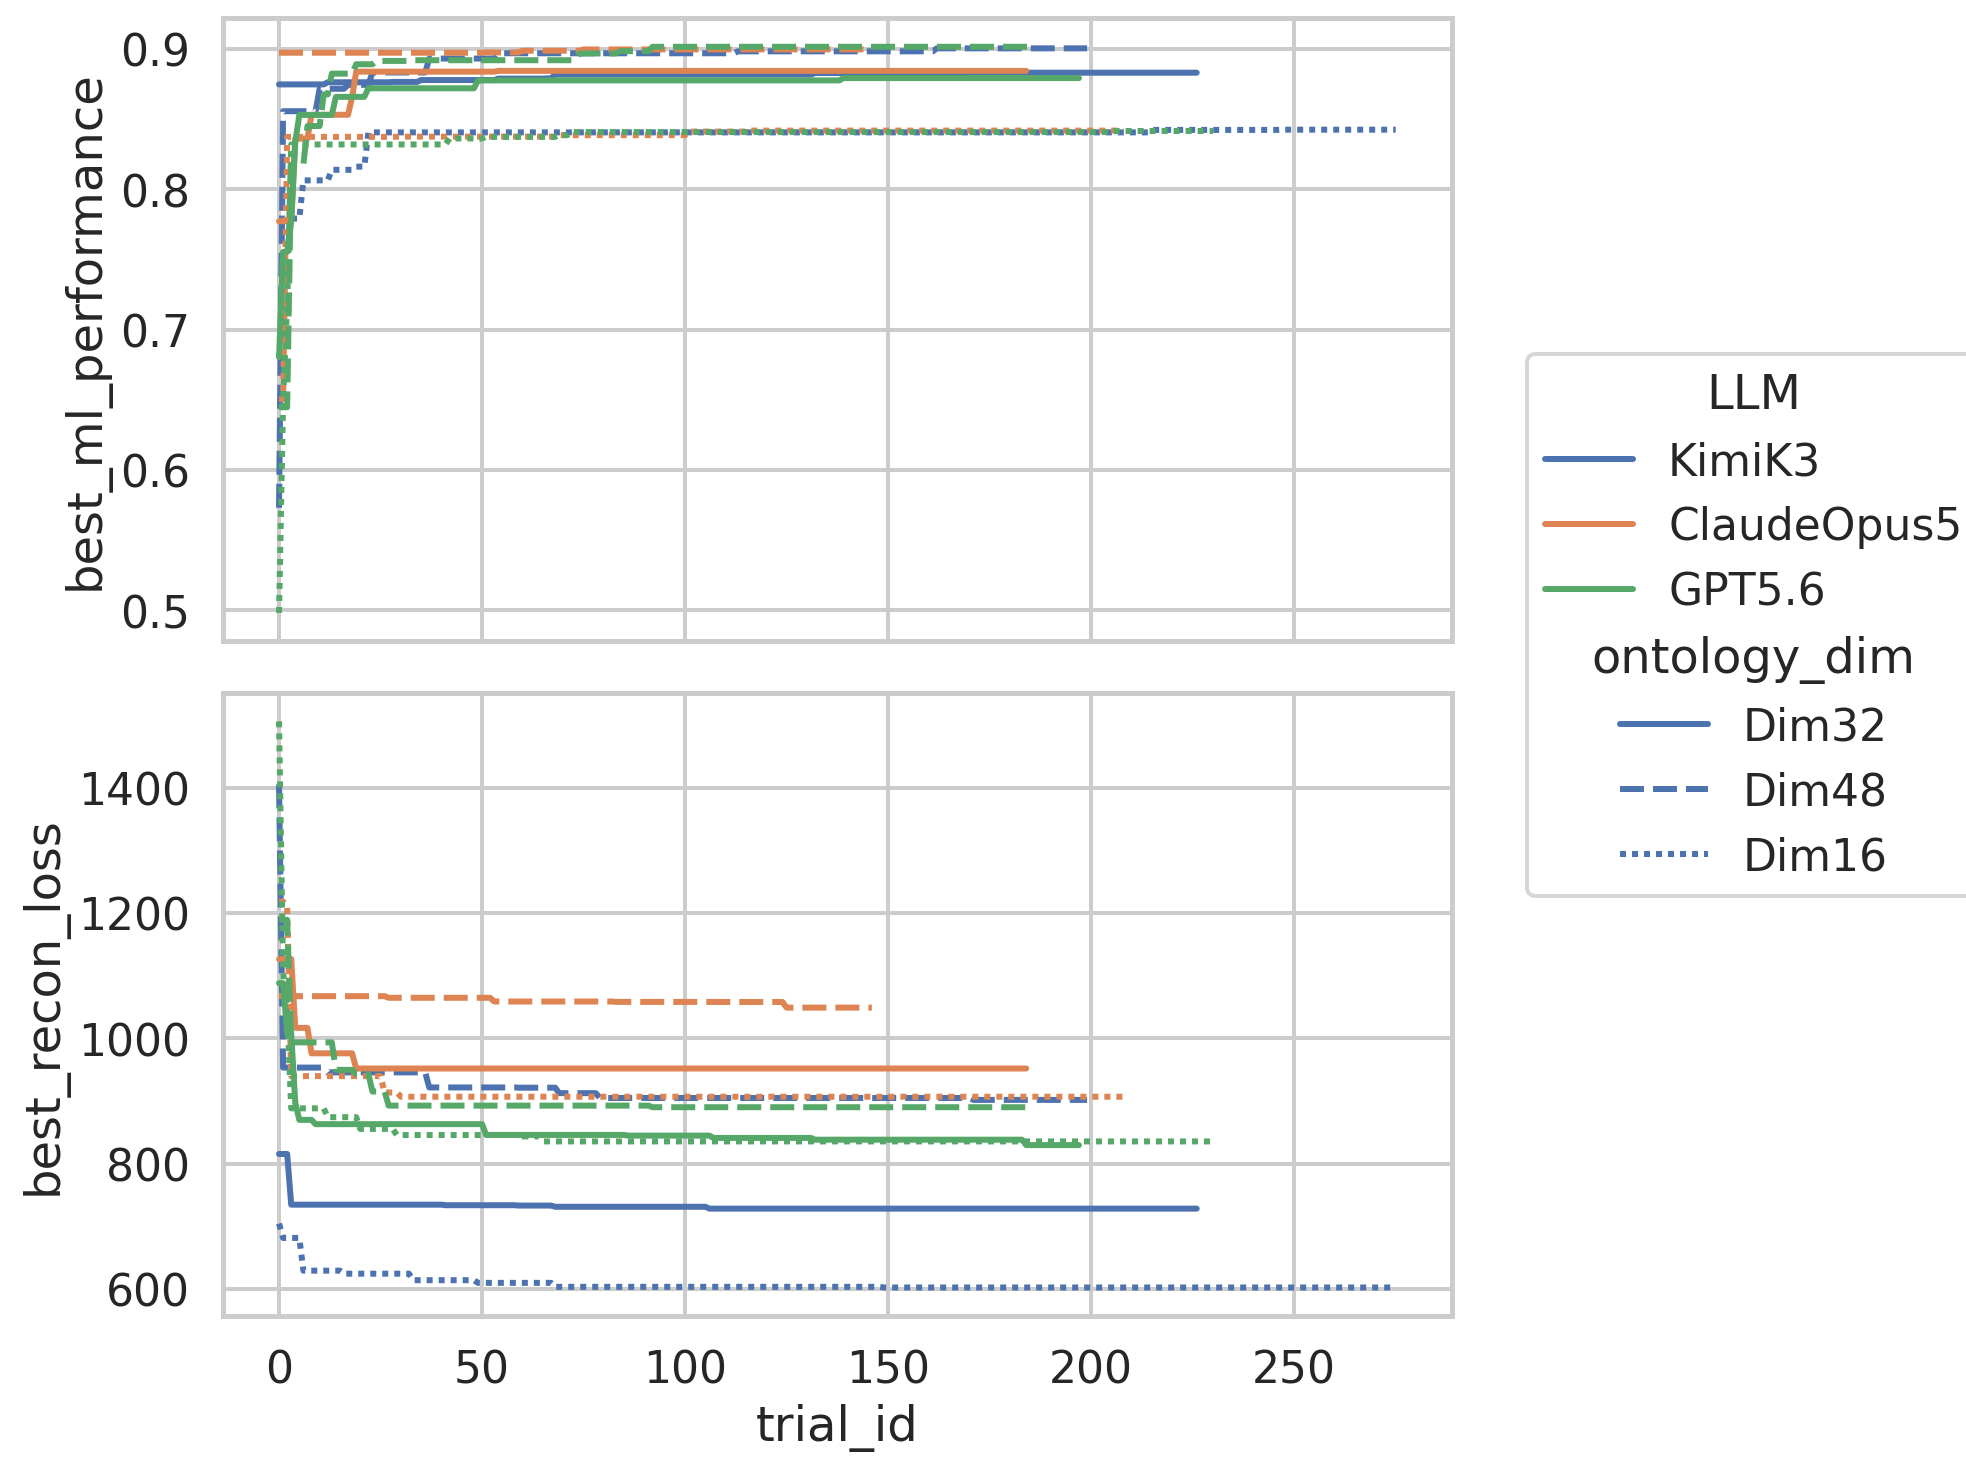

In [ ]:
import seaborn.objects as so
from seaborn import plotting_context
from seaborn import axes_style
(
	so.Plot(plot_df, x="trial_id", color="LLM", linestyle="ontology_dim")
	.pair(y=["best_ml_performance", "best_recon_loss"])
	.add(so.Line())
	.layout(size=(8, 8))
	.theme(axes_style("whitegrid") | plotting_context("talk"))
)



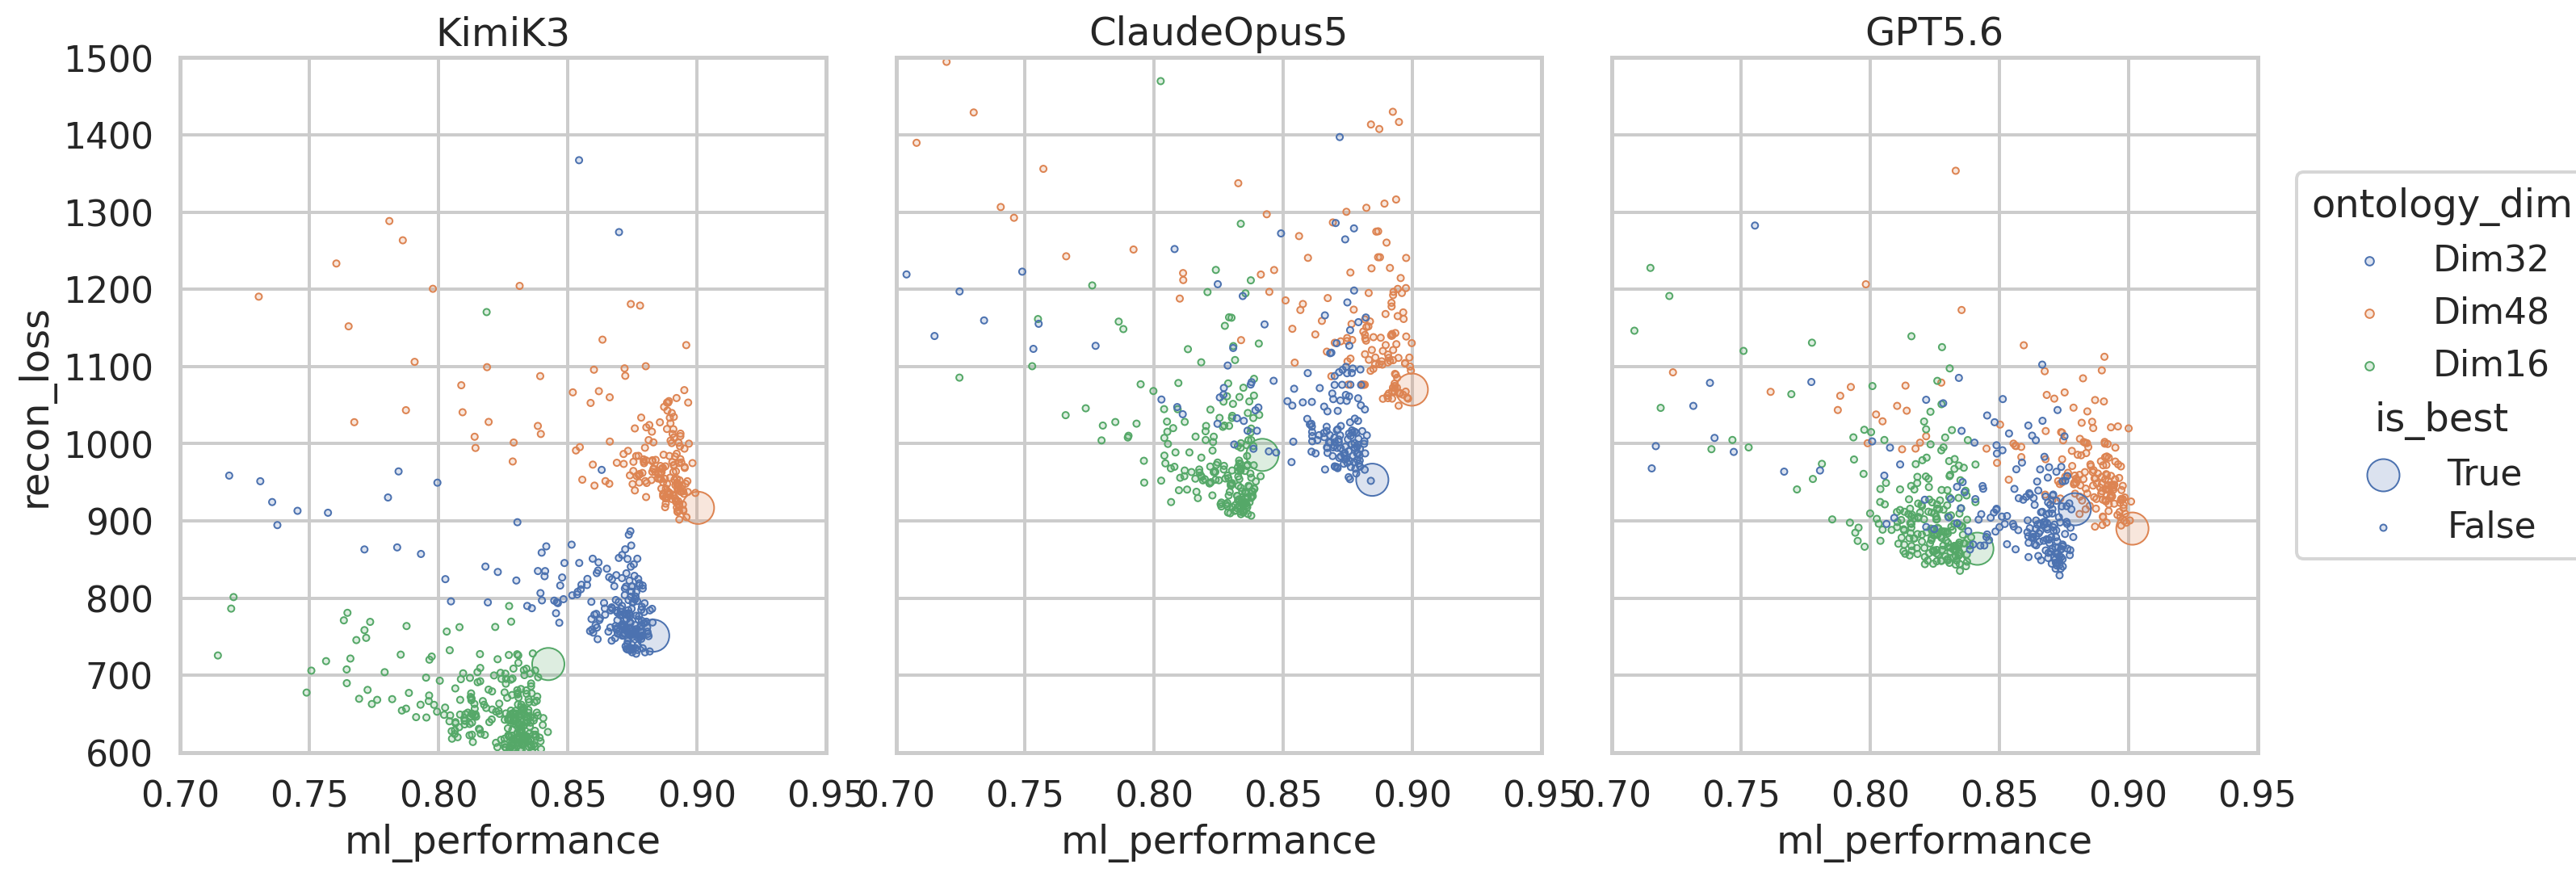

In [ ]:
(
	so.Plot(plot_df, x="ml_performance", y="recon_loss", color="ontology_dim", pointsize="is_best")
	.facet("LLM")
	.add(so.Dots())
	.scale(pointsize={True: 15, False: 3})
	.limit(y=(600, 1500), x=(0.7, 0.95))
	.layout(size=(15, 6))
	.theme(axes_style("whitegrid") | plotting_context("talk"))
)

## Spearman rank correlation between ml_performance and recon_loss for each ontology_dim and LLM



In [129]:
spearman_corr_df = (
	plot_df
	.groupby(["ontology_dim", "LLM"])
	.apply(
		lambda g: pd.Series({
			"n_trials": g.shape[0],
			"spearman_corr": g["ml_performance"].corr(g["recon_loss"], method="spearman")
		})
	)
	.reset_index()
	.sort_values(["ontology_dim", "LLM"])
)

spearman_corr_df

,ontology_dim,LLM,n_trials,spearman_corr
0,Dim16,ClaudeOpus5,209.0,-0.429066
1,Dim16,GPT5.6,230.0,-0.425351
2,Dim16,KimiK3,276.0,-0.469307
3,Dim32,ClaudeOpus5,185.0,-0.473178
4,Dim32,GPT5.6,197.0,-0.525195
5,Dim32,KimiK3,227.0,-0.590099
6,Dim48,ClaudeOpus5,147.0,-0.522369
7,Dim48,GPT5.6,186.0,-0.680209
8,Dim48,KimiK3,199.0,-0.560472


### Hyperparam visualization



In [ ]:
log_scale_params = [
	"config_learning_rate",
	"config_weight_decay",
	"config_beta",
]

for param in log_scale_params:
	plot_df[f'log_{param}'] = np.log10(plot_df[param])
 
hyperparams_selected = [
	"log_config_learning_rate",
	"config_batch_size",		
	"log_config_weight_decay",
	"config_drop_p",
	"config_enc_factor",
	"log_config_beta",
	###
	"ontology_name",
	"ml_performance",
	"is_best"
]

## long format for stripplot 
plot_df_long = plot_df.melt(id_vars=['ontology_name', 'LLM','ontology_dim', 'trial_id', 'ml_performance', 'recon_loss', 'is_best'], 
							value_vars=hyperparams_selected[:-3], 
							var_name='hyperparameter', 
							value_name='value')

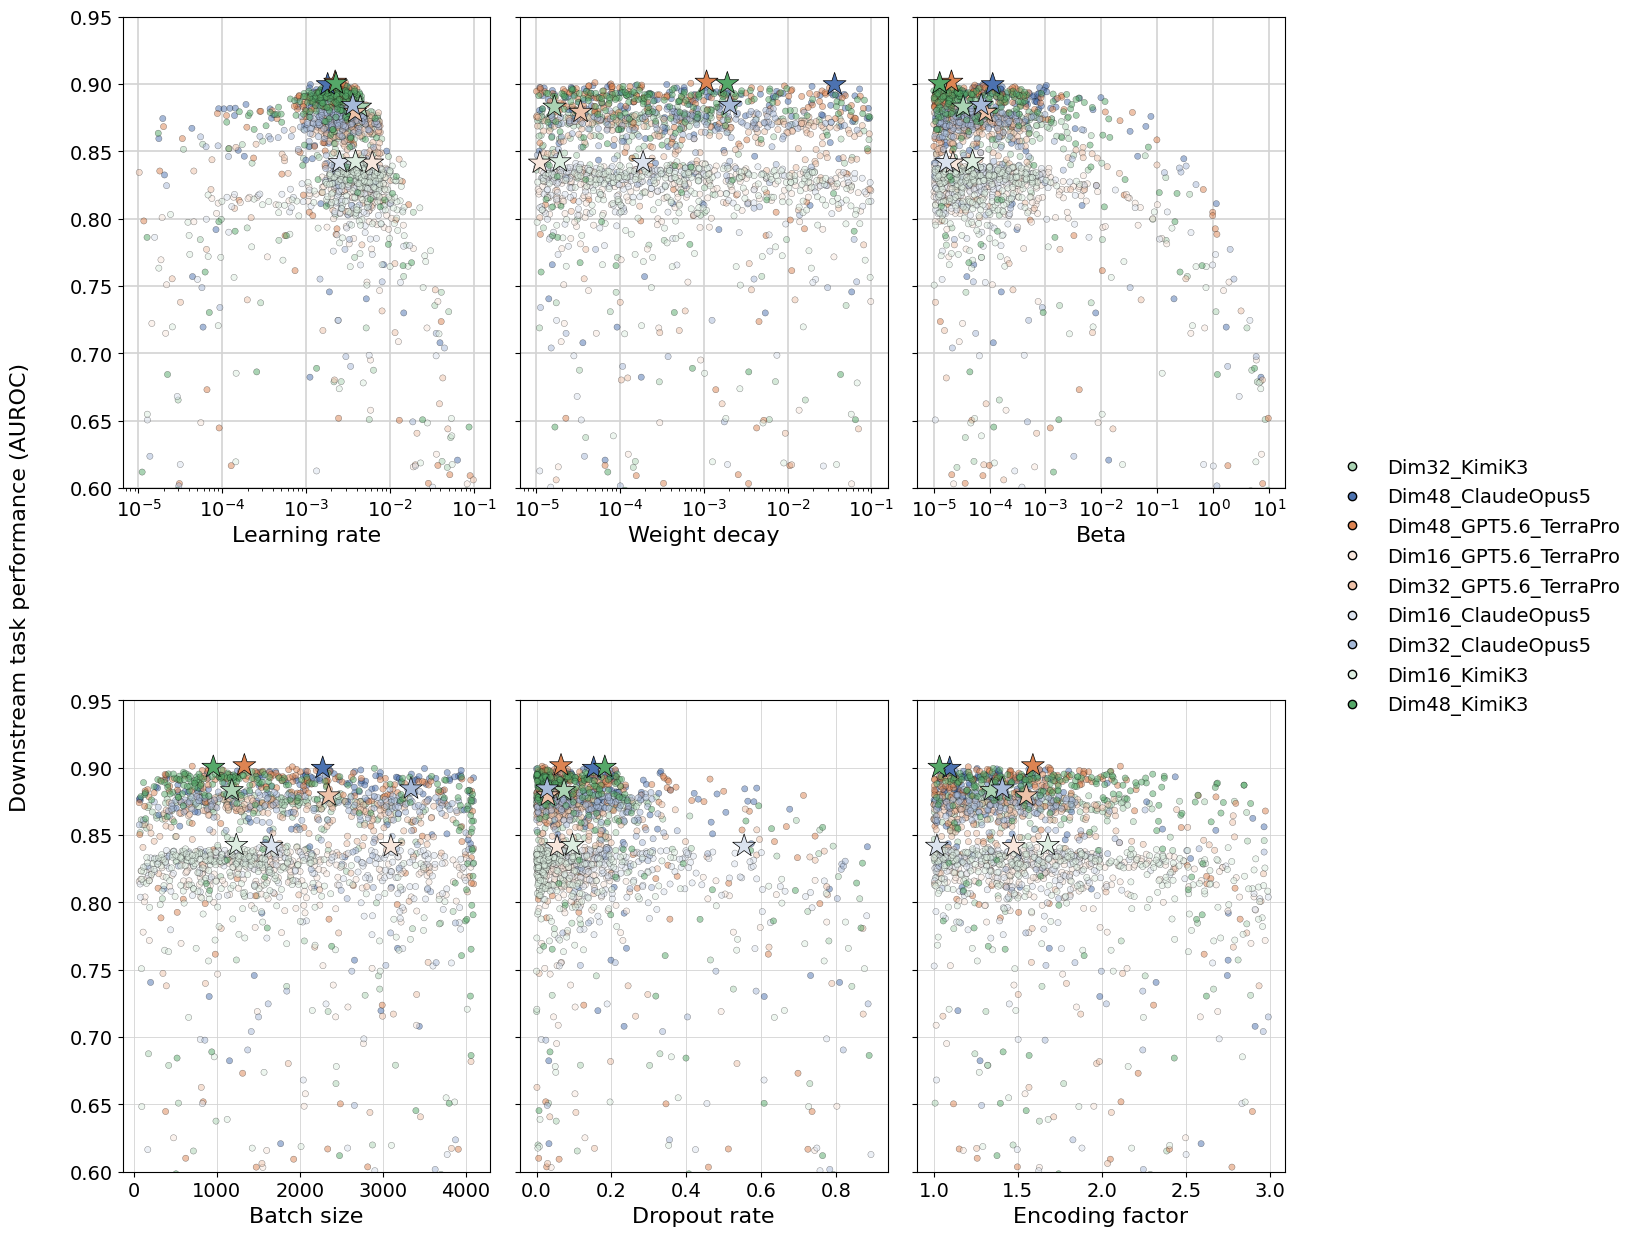

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.ticker import LogLocator

## Build a palette with one base color per LLM, shaded light->dark by dimension (16, 32, 48)
llm_base_colors = {
	"ClaudeOpus5": "#4C72B0",      # blue
	"GPT5.6_TerraPro": "#DD8452",  # orange
	"KimiK3": "#55A868",           # green
}
dim_shades = {"Dim16": 0.2, "Dim32": 0.5, "Dim48": 1.0}  # light -> dark/saturated

def shade_color(hex_color, factor):
	rgb = mcolors.to_rgb(hex_color)
	white = (1.0, 1.0, 1.0)
	return tuple(w + (c - w) * factor for w, c in zip(white, rgb))

ontology_palette = {}
for name in plot_df_long["ontology_name"].unique():
	dim_str, *rest = name.split("_")
	llm = "_".join(rest) if rest else "Varix"
	base = llm_base_colors.get(llm, "#888888")
	factor = dim_shades.get(dim_str, 1.0)
	ontology_palette[name] = shade_color(base, factor)

## Panels: top row = hyperparameters on a log-scaled axis, bottom row = linear axis.
## Raw values are plotted; the scale is applied to the axis itself (log ticks as 10^n).
panels = [
	[("config_learning_rate", "Learning rate", "log"), ("config_weight_decay", "Weight decay", "log"), ("config_beta", "Beta", "log")],
	[("config_batch_size", "Batch size", "linear"), ("config_drop_p", "Dropout rate", "linear"), ("config_enc_factor", "Encoding factor", "linear")],
]
row_titles = ["Logarithmic x-axes", "Linear x-axes"]
log_bg = "#EEF2F8"  # light tint marks log-scaled panels
fs = 16

best_mask = plot_df["is_best"].astype(bool)
rest_df, best_df = plot_df[~best_mask], plot_df[best_mask]

fig, axes = plt.subplots(2, 3, figsize=(15, 15), sharey=True, gridspec_kw=dict(hspace=0.45, wspace=0.08))
for r, row in enumerate(panels):
	for c, (col, label, scale) in enumerate(row):
		ax = axes[r, c]
		sns.scatterplot(data=rest_df, x=col, y="ml_performance", hue="ontology_name", palette=ontology_palette,
						s=20, alpha=0.5, edgecolor="black", linewidth=0.3, legend=False, ax=ax)
		sns.scatterplot(data=best_df, x=col, y="ml_performance", hue="ontology_name", palette=ontology_palette,
						marker="*", s=300, edgecolor="black", linewidth=0.5, legend=False, ax=ax)
		if scale == "log":
			ax.set_xscale("log")
			ax.xaxis.set_major_locator(LogLocator(base=10, numticks=15))  # one labeled tick per decade
			ax.grid(True, which="major", color="lightgray", lw=1.2)
		else:
			ax.grid(True, color="lightgray", lw=0.6)
		ax.set_axisbelow(True)
		ax.set_xlabel(label, fontsize=fs)
		ax.set_ylabel("")  # shared y-label set via fig.supylabel
		ax.tick_params(labelsize=fs - 2)
		ax.tick_params(axis="y", labelleft=(c == 0))


axes[0, 0].set_ylim(0.6, 0.95)
fig.supylabel("Downstream task performance (AUROC)", fontsize=fs, x=0.05)

# Legend kept outside of the plot (post-processed separately)
handles = [Line2D([], [], marker="o", ls="", color=col, markeredgecolor="black", label=name) for name, col in ontology_palette.items()]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(0.92, 0.5), frameon=False, fontsize=fs - 2)
plt.show()


# Model statistics 

Collect for each final model: 
- total number of model parameters
- Encoder structure: input and hidden layer dimensions
- Latent dimension
- Decoder structure: Hidden layer dimension, sparsity of each layer (percent of connections with zero weight)
- hyperparameter configuration for training
	- learning rate
	- weight decay
	- epochs
	- batch size
	- dropout rate
	- encoding factor
	- beta

In [3]:
import os
import pandas as pd
import autoencodix as acx
import torch

# Architecture key -> pipeline class and results folder (files: large_<key>_final_model_<model_id>.pkl)
MODEL_SPECS = {
	"ontix": {
		"class": acx.Ontix,
		"results_folder": "../results/large_ontix_save/run_Aug26",
	},
	"varix": {
		"class": acx.Varix,
		"results_folder": "../results/large_varix_save/run_Aug26",
	},
	"disentanglix": {
		"class": acx.Disentanglix,
		"results_folder": "../results/large_disentanglix_save/run_Aug26",
	},
}

root_folder = os.path.abspath("..")  # notebook runs from notebooks/, repo root is one level up

model_ids = [
	"Dim16_ClaudeOpus5", "Dim32_ClaudeOpus5", "Dim48_ClaudeOpus5",
	"Dim16_KimiK3", "Dim32_KimiK3", "Dim48_KimiK3",
	"Dim16_GPT5.6_TerraPro", "Dim32_GPT5.6_TerraPro", "Dim48_GPT5.6_TerraPro",
	"Dim16_Varix", "Dim32_Varix", "Dim48_Varix",
	"Dim16_Disentanglix", "Dim32_Disentanglix", "Dim48_Disentanglix",
]

def collect_model_stats(model_id):
	# Find architecture by checking which final model file exists
	for mtype, spec in MODEL_SPECS.items():
		f = os.path.join(spec["results_folder"], f"large_{mtype}_final_model_{model_id}.pkl")
		if os.path.exists(f):
			break
	else:
		raise FileNotFoundError(f"No trained model found for '{model_id}'")

	m = spec["class"].load(file_path=f)
	net, cfg = m.result.model, m.config

	# Decoder sparsity per layer (fraction of zeros in mask); unmasked decoders (Varix, Disentanglix) are dense by design
	masks = getattr(net, "masks", None)
	if masks is not None and len(masks) > 0:
		sparsity = [round((mk == 0).sum().item() / mk.numel(), 4) for mk in masks]
	else:
		sparsity = [0.0] * sum(isinstance(l, torch.nn.Linear) for l in net._decoder)

	stats = {
		"model_id": model_id,
		"architecture": mtype,
		"n_params_total": sum(p.numel() for p in net.parameters()),
		"n_params_nonzero": sum(int((p.abs() >= 0.01).sum()) for p in net.parameters()),
		"input_dim": net.input_dim,
		"encoder_hidden": [s.out_features for s in net._encoder if hasattr(s, "out_features")],
		"latent_dim": cfg.latent_dim,
		"decoder_hidden": [s.out_features for s in net._decoder if hasattr(s, "out_features")][:-1],
		"decoder_sparsity": sparsity,
		"learning_rate": cfg.learning_rate,
		"weight_decay": cfg.weight_decay,
		"epochs": cfg.epochs,
		"batch_size": cfg.batch_size,
		"drop_p": cfg.drop_p,
		"enc_factor": cfg.enc_factor,
		"beta": cfg.beta,
	}
	return stats

model_stats = []
for mid in model_ids:
	print(f"Collecting {mid} ...")
	try:
		model_stats.append(collect_model_stats(mid))
	except Exception as e:
		print(f"  skipped: {e}")

model_stats_df = pd.DataFrame(model_stats).set_index("model_id")

out_file = os.path.join(root_folder, "results", "model_statistics.tsv")
model_stats_df.to_csv(out_file, sep="\t")
print(f"Saved to {out_file}")
model_stats_df

Attempting to load a pipeline from ../results/large_ontix_save/run_Aug26/large_ontix_final_model_Dim16_ClaudeOpus5.pkl...
Pipeline object loaded successfully. Actual type: Ontix
Preprocessor loaded successfully.
Attempting to load a pipeline from ../results/large_ontix_save/run_Aug26/large_ontix_final_model_Dim32_ClaudeOpus5.pkl...
Pipeline object loaded successfully. Actual type: Ontix
Preprocessor loaded successfully.
Attempting to load a pipeline from ../results/large_ontix_save/run_Aug26/large_ontix_final_model_Dim48_ClaudeOpus5.pkl...
Pipeline object loaded successfully. Actual type: Ontix
Preprocessor loaded successfully.
Attempting to load a pipeline from ../results/large_ontix_save/run_Aug26/large_ontix_final_model_Dim16_KimiK3.pkl...
Pipeline object loaded successfully. Actual type: Ontix
Preprocessor loaded successfully.
Attempting to load a pipeline from ../results/large_ontix_save/run_Aug26/large_ontix_final_model_Dim32_KimiK3.pkl...
Pipeline object loaded successfully. Act

,architecture,n_params_total,n_params_nonzero,input_dim,encoder_hidden,latent_dim,decoder_hidden,decoder_sparsity,learning_rate,weight_decay,epochs,batch_size,drop_p,enc_factor,beta
model_id,,,,,,,,,,,,,,,
Dim16_ClaudeOpus5,ontix,373278386,365682275,9006,"[8845, 8687, 8531, 8378, 8228]",16,[207],"[0.9369, 0.9907]",0.002501,0.000188,500,1659,0.554198,1.018178,0.000017
Dim32_ClaudeOpus5,ontix,151665939,138234435,10331,"[7339, 5213, 3703, 2630, 1868]",32,[332],"[0.9687, 0.9935]",0.003603,0.002044,500,3339,0.028377,1.407685,0.000071
Dim48_ClaudeOpus5,ontix,520271380,370581451,12499,"[11420, 10434, 9534, 8711, 7959]",48,[446],"[0.9791, 0.9949]",0.001806,0.036373,500,2276,0.152559,1.094394,0.000113
Dim16_KimiK3,ontix,27390717,26595685,5401,"[3216, 1915, 1140, 679, 404]",16,[109],"[0.9375, 0.984]",0.003883,0.000019,500,1235,0.096160,1.678927,0.000049
Dim32_KimiK3,ontix,88013565,86437257,7396,"[5510, 4105, 3058, 2278, 1697]",32,[147],"[0.9688, 0.9864]",0.004416,0.000016,500,1181,0.073552,1.342253,0.000034
Dim48_KimiK3,ontix,384717699,300491358,9462,"[9157, 8862, 8576, 8300, 8032]",48,[228],"[0.9791, 0.9898]",0.002264,0.001904,500,958,0.182300,1.033243,0.000013
Dim16_GPT5.6_TerraPro,ontix,86953085,85143202,8357,"[5666, 3841, 2604, 1765, 1196]",16,[124],"[0.9375, 0.9862]",0.006145,0.000011,500,3097,0.054823,1.474796,0.000022
Dim32_GPT5.6_TerraPro,ontix,105136438,101512351,9749,"[6287, 4054, 2614, 1685, 1086]",32,[143],"[0.9685, 0.989]",0.003839,0.000034,500,2348,0.030228,1.550659,0.000085
Dim48_GPT5.6_TerraPro,ontix,101904169,96411061,9827,"[6182, 3889, 2446, 1538, 967]",48,[223],"[0.979, 0.9916]",0.002221,0.001074,500,1332,0.065454,1.589611,0.000021
